# Universidad Amazónica de Pando
## Carrera de Ingeniería de Sistemas
### Ingeniería de Software I

**Análisis de las características habitacionales de los hogares bolivianos según la Encuesta de Hogares 2023**

**Docente:** Ph. D. Juan Carlos Huanca Guanca  
**Autor:** Cristopher Angel Coaquira  Guayhua

**R.U.:** 38203
**Lugar:** Cobija, Bolivia  
**Gestión:** 2026

---

## Perfil del estudio

La disponibilidad de vivienda adecuada, servicios básicos y espacio suficiente constituye una dimensión central de las condiciones de vida. Este análisis describe características físicas y de acceso a servicios de los hogares observados por la Encuesta de Hogares 2023 del Instituto Nacional de Estadística (INE). El archivo de trabajo contiene una observación por vivienda/hogar y cubre los nueve departamentos y las áreas urbana y rural.

**Objetivo.** Describir las características habitacionales observadas y presentar estimaciones ponderadas de materiales de paredes y fuente de agua, distinguiendo claramente las estadísticas de muestra de las estimaciones de población.

**Preguntas analíticas preliminares.** ¿Qué materiales predominan en las paredes? ¿Cuáles son las fuentes de agua reportadas? ¿Cómo se distribuyen el número de personas y de habitaciones? ¿Cómo difieren las características entre áreas urbana y rural? ¿Qué asociación descriptiva existe entre tamaño del hogar y habitaciones ocupadas?

**Selección.** La base oficial resulta pertinente porque mide directamente vivienda, tenencia, materiales, agua, saneamiento, energía, residuos, cocina, habitaciones e internet; además supera ampliamente el mínimo de 600 observaciones. El catálogo ANDA clasifica el archivo como de uso público. Se preserva el original y el cuaderno no exporta registros individuales.

**Fuente y metadatos:** [INE, Encuesta de Hogares 2023 (ANDA)](https://anda.ine.gob.bo/index.php/catalog/108), [diccionario de EH2023_Vivienda](https://anda.ine.gob.bo/index.php/catalog/108/data-dictionary/F2?file_name=EH2023_Vivienda), [materiales relacionados y diseño muestral](https://fm.ine.gob.bo/index.php/catalog/108/related-materials). La documentación publicada señala 12.815 casos y 36 variables. La copia local se verifica por separado y contiene una variable adicional, `Factor_Rev2025`.

**Diseño muestral.** El catálogo identifica `factor` como el factor de expansión y describe selección de UPM con probabilidad proporcional al tamaño y selección sistemática de viviendas. El archivo local añade `Factor_Rev2025`; el INE informa que sus series actualizadas usan factores ajustados a las Proyecciones de Población, revisión 2025. Por ello, los estimadores puntuales de población de este cuaderno usan `Factor_Rev2025`, mientras `factor` se conserva en el diccionario como el ponderador original. No se calculan errores estándar ni intervalos de confianza del diseño complejo; las conclusiones inferenciales quedan limitadas.

**Alcance.** Las estadísticas sin ponderar describen la muestra observada. Las tablas ponderadas son estimaciones puntuales con el factor indicado y no sustituyen un análisis de varianza que incorpore conglomerados y estratos.

**Limitaciones previstas.** El diseño es muestral; los módulos tienen saltos que producen faltantes estructurales; las variables de diseño se encuentran anonimizadas; el cuaderno no estima incertidumbre del diseño; y la copia local contiene una columna que no aparece en el listado de 36 variables del catálogo.

### Preparación del archivo

En una instalación local se utiliza por defecto la ruta original entregada. En Jupyter/Colab, se puede definir `EH2023_SAV_PATH` o editar la ruta en la siguiente celda. Instale las dependencias declaradas en `pyproject.toml` antes de ejecutar.

## 1. Explicación — configuración y lectura
Se leerá el SAV sin aplicar formatos de valor para conservar códigos numéricos y etiquetas en metadatos separados. No se modifica ni se sobrescribe el archivo fuente.

In [1]:
from pathlib import Path
import os
import json
import math
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadstat
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9})

ROOT = Path.cwd()
RUTA_SAV = Path(os.environ.get(
    "EH2023_SAV_PATH",
    "/home/usic03/Descargas/BD_EH2023/EH2023_Vivienda.sav"
))
if not RUTA_SAV.exists() and (ROOT / "data" / "EH2023_Vivienda.sav").exists():
    RUTA_SAV = ROOT / "data" / "EH2023_Vivienda.sav"
if not RUTA_SAV.exists():
    raise FileNotFoundError(
        "No se encontró el SAV. Defina EH2023_SAV_PATH con la ruta local "
        "o coloque EH2023_Vivienda.sav en data/."
    )

CARPETA_EXPORTACIONES = ROOT / "exportaciones_eh2023"
CARPETA_EXPORTACIONES.mkdir(parents=True, exist_ok=True)

## 2. Resultado — dimensiones y metadatos
La siguiente lectura conserva los valores originales de las variables y devuelve los metadatos SPSS. El resultado reporta dimensiones locales comprobadas.

In [2]:
CODIGO_EXTRACTO_LITERAL = """datos, metadatos = pyreadstat.read_sav(str(RUTA_SAV), apply_value_formats=False)
assert datos.shape[0] > 600
print(f\"Dimensiones verificadas: {datos.shape[0]:,} registros × {datos.shape[1]} variables\")"""
exec(CODIGO_EXTRACTO_LITERAL)

etiquetas_variables = metadatos.column_names_to_labels or {}
etiquetas_valores = metadatos.variable_value_labels or {}
print(f"Codificación de texto: {metadatos.file_encoding}")
print(f"Etiquetas descriptivas disponibles: {len(etiquetas_variables)}")
print(f"Variables con etiquetas categóricas: {len(etiquetas_valores)}")
print(f"Campos de faltantes especiales declarados por SPSS: {len(metadatos.missing_ranges or {}) + len(metadatos.missing_user_values or {})}")
display(pd.DataFrame({
    "variable": datos.columns,
    "tipo_python": [str(datos[c].dtype) for c in datos.columns],
    "etiqueta_original_INE": [etiquetas_variables.get(c, "") for c in datos.columns],
}))

Dimensiones verificadas: 12,815 registros × 37 variables
Codificación de texto: windows-1252
Etiquetas descriptivas disponibles: 37
Variables con etiquetas categóricas: 20
Campos de faltantes especiales declarados por SPSS: 0


,variable,tipo_python,etiqueta_original_INE
0,folio,str,Id hogar anonimizado
1,depto,float64,Departamento
2,area,float64,Urbana Rural
3,totper,float64,Total de personas
4,s06a_01,float64,La vivienda es:
5,s06a_02,float64,La vivienda que ocupa este hogar es:
6,s06a_02e,str,La vivienda que ocupa el hogar es... Otra? (Especifique)
7,s06a_03,float64,¿Cuál es el material de construcción más utilizado en las paredes de esta vivienda?
8,s06a_03e,str,¿Cuál es el material de construcción más utilizado en las paredes de esta vivienda? OTRO (Especi...
9,s06a_04,float64,¿Las paredes interiores de esta vivienda tienen revoque?


## 3. Explicación — unidad de análisis y diccionario
La unidad es el registro de vivienda/hogar de la sección 6. Los códigos categóricos se interpretan con las etiquetas SPSS; no se usan como cantidades. Los ejemplos de identificadores y respuestas abiertas se enmascaran para no divulgar registros.

In [3]:
variables_cuantitativas = {"totper", "s06a_08a", "s06a_08b", "s06a_16", "s06a_17"}
variables_conteo = {"totper", "s06a_08a", "s06a_16", "s06a_17"}
variables_id = {"folio", "upm", "estrato"}
variables_peso = {"factor", "Factor_Rev2025"}
variables_texto = {c for c in datos.select_dtypes(include=["object", "str"]).columns}
texto_abierto = variables_texto - variables_id

def tipo_analitico(variable):
    if variable in variables_id:
        return "Identificador/diseño nominal"
    if variable in variables_peso:
        return "Cuantitativa continua (factor de expansión)"
    if variable in variables_cuantitativas:
        return "Cuantitativa discreta (conteo)" if variable in variables_conteo else "Cuantitativa discreta"
    if variable in texto_abierto:
        return "Categórica nominal (texto abierto)"
    return "Categórica nominal (código numérico)"

def ejemplo_seguro(variable):
    serie = datos[variable]
    no_nulos = serie.dropna()
    if variable in variables_id:
        return "Valor observado; identificador suprimido"
    if variable in texto_abierto:
        no_vacios = no_nulos.astype("string").str.strip().ne("")
        return "Respuesta textual observada; contenido suprimido" if no_vacios.any() else "Cadena vacía observada"
    if no_nulos.empty:
        return "Sin valor observado"
    valor = no_nulos.iloc[0]
    mapa = etiquetas_valores.get(variable, {})
    claves = [valor, str(valor)]
    if isinstance(valor, (int, float, np.number)):
        claves.extend([str(float(valor)), f"{float(valor):g}"])
    etiqueta = next((mapa[clave] for clave in claves if clave in mapa), None)
    if etiqueta:
        return f"{valor:g} = {etiqueta}" if isinstance(valor, (int, float, np.number)) else f"{valor} = {etiqueta}"
    return str(valor)

filas_diccionario = []
for variable in datos.columns:
    serie = datos[variable]
    categorias = etiquetas_valores.get(variable, {})
    categorias_texto = "; ".join(f"{k}: {v}" for k, v in categorias.items())
    rol = (
        "Identificador único de hogar" if variable == "folio" else
        "Variable de conglomerado/UPM" if variable == "upm" else
        "Variable de estratificación" if variable == "estrato" else
        "Factor de expansión original" if variable == "factor" else
        "Factor revisado con EPP 2025; ponderador utilizado" if variable == "Factor_Rev2025" else
        "Desagregación geográfica" if variable in {"depto", "area"} else
        "Variable cuantitativa principal" if variable in {"totper", "s06a_16", "s06a_17"} else
        "Respuesta abierta complementaria" if variable in texto_abierto else
        "Variable de caracterización habitacional"
    )
    filas_diccionario.append({
        "nombre_original": variable,
        "etiqueta_original_INE": etiquetas_variables.get(variable, ""),
        "etiquetas_de_valores_INE": categorias_texto,
        "ejemplo_real_seguro": ejemplo_seguro(variable),
        "tipo_tecnico": str(serie.dtype),
        "tipo_analitico": tipo_analitico(variable),
        "rol": rol,
        "nulos_SAV": int(serie.isna().sum()),
    })
diccionario = pd.DataFrame(filas_diccionario)
diccionario.to_csv(CARPETA_EXPORTACIONES / "diccionario_variables.csv", index=False, encoding="utf-8-sig")
display(diccionario)
print(f"Unidad de observación: vivienda/hogar; {len(datos):,} registros.")

,nombre_original,etiqueta_original_INE,etiquetas_de_valores_INE,ejemplo_real_seguro,tipo_tecnico,tipo_analitico,rol,nulos_SAV
0,folio,Id hogar anonimizado,,Valor observado; identificador suprimido,str,Identificador/diseño nominal,Identificador único de hogar,0
1,depto,Departamento,1.0: Chuquisaca; 2.0: La Paz; 3.0: Cochabamba; 4.0: Oruro; 5.0: Potosí; 6.0: Tarija; 7.0: Santa ...,1 = Chuquisaca,float64,Categórica nominal (código numérico),Desagregación geográfica,0
2,area,Urbana Rural,1.0: Urbano; 2.0: Rural,1 = Urbano,float64,Categórica nominal (código numérico),Desagregación geográfica,0
3,totper,Total de personas,,5.0,float64,Cuantitativa discreta (conteo),Variable cuantitativa principal,0
4,s06a_01,La vivienda es:,1.0: 1. Casa; 2.0: 2. Choza/ Pahuichi; 3.0: 3. Departamento; 4.0: 4. Cuarto(s) o habitacion(es) ...,1 = 1. Casa,float64,Categórica nominal (código numérico),Variable de caracterización habitacional,0
5,s06a_02,La vivienda que ocupa este hogar es:,1.0: 1. ¿Propia y totalmente pagada?; 2.0: 2. ¿Propia y la están pagando?; 3.0: 3. ¿Alquilada?; ...,1 = 1. ¿Propia y totalmente pagada?,float64,Categórica nominal (código numérico),Variable de caracterización habitacional,0
6,s06a_02e,La vivienda que ocupa el hogar es... Otra? (Especifique),,Respuesta textual observada; contenido suprimido,str,Categórica nominal (texto abierto),Respuesta abierta complementaria,0
7,s06a_03,¿Cuál es el material de construcción más utilizado en las paredes de esta vivienda?,1.0: 1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN; 2.0: 2. ADOBE / TAPIAL; 3.0: 3. TABIQUE/ QUINCHE...,1 = 1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN,float64,Categórica nominal (código numérico),Variable de caracterización habitacional,0
8,s06a_03e,¿Cuál es el material de construcción más utilizado en las paredes de esta vivienda? OTRO (Especi...,,Respuesta textual observada; contenido suprimido,str,Categórica nominal (texto abierto),Respuesta abierta complementaria,0
9,s06a_04,¿Las paredes interiores de esta vivienda tienen revoque?,1.0: 1. Si; 2.0: 2. No,2 = 2. No,float64,Categórica nominal (código numérico),Variable de caracterización habitacional,0


Unidad de observación: vivienda/hogar; 12,815 registros.


## 4. Explicación — auditoría de calidad
Se contabilizan los nulos del archivo, las cadenas vacías por separado, los valores distintos y la unicidad. Se contrasta `folio` como clave candidata y se buscan duplicados exactos. Los nulos en preguntas condicionadas se interpretan como posibles saltos de cuestionario.

In [4]:
auditoria = pd.DataFrame({
    "nombre_original": datos.columns,
    "tipo_reconocido": [str(datos[c].dtype) for c in datos.columns],
    "nulos": [int(datos[c].isna().sum()) for c in datos.columns],
    "porcentaje_nulos": [datos[c].isna().mean() * 100 for c in datos.columns],
    "valores_unicos": [int(datos[c].nunique(dropna=True)) for c in datos.columns],
    "porcentaje_unicidad": [datos[c].nunique(dropna=True) / len(datos) * 100 for c in datos.columns],
    "cadenas_vacias": [int(datos[c].astype("string").str.strip().eq("").sum()) if c in variables_texto else 0 for c in datos.columns],
})
auditoria.to_csv(CARPETA_EXPORTACIONES / "auditoria_calidad.csv", index=False, encoding="utf-8-sig")
duplicados = int(datos.duplicated().sum())
folio_unicos = int(datos["folio"].nunique(dropna=True))
assert folio_unicos == len(datos), "folio no resultó único; no afirmar clave única"
assert duplicados == 0, "se detectaron duplicados exactos"

campos_faltantes = auditoria.loc[auditoria["nulos"] > 0].sort_values("nulos", ascending=False)
hallazgos_calidad = [
    f"No hay filas duplicadas exactas ({duplicados:,}) y folio identifica los {folio_unicos:,} registros sin repetición.",
    f"El máximo de nulos está en s06a_21: {int(auditoria.set_index('nombre_original').loc['s06a_21','nulos']):,} ({auditoria.set_index('nombre_original').loc['s06a_21','porcentaje_nulos']:.2f} %); es una pregunta de conexión fija y presenta salto de cuestionario.",
    f"La variable de agua semanal s06a_08a tiene {int(auditoria.set_index('nombre_original').loc['s06a_08a','nulos']):,} nulos ({auditoria.set_index('nombre_original').loc['s06a_08a','porcentaje_nulos']:.2f} %); se reportan como faltantes del archivo y no se imputan.",
]
print("Duplicados exactos:", duplicados)
print("folio único:", folio_unicos == len(datos), f"({folio_unicos:,} valores distintos)")
display(auditoria)
display(Markdown("### Tres hallazgos de calidad\n" + "\n".join(f"{i}. {h}" for i, h in enumerate(hallazgos_calidad, 1))))

Duplicados exactos: 0
folio único: True (12,815 valores distintos)


,nombre_original,tipo_reconocido,nulos,porcentaje_nulos,valores_unicos,porcentaje_unicidad,cadenas_vacias
0,folio,str,0,0.000000,12815,100.000000,0
1,depto,float64,0,0.000000,9,0.070230,0
2,area,float64,0,0.000000,2,0.015607,0
3,totper,float64,0,0.000000,13,0.101444,0
4,s06a_01,float64,0,0.000000,6,0.046820,0
5,s06a_02,float64,0,0.000000,8,0.062427,0
6,s06a_02e,str,0,0.000000,3,0.023410,12813
7,s06a_03,float64,0,0.000000,7,0.054623,0
8,s06a_03e,str,0,0.000000,7,0.054623,12808
9,s06a_04,float64,0,0.000000,2,0.015607,0


### Tres hallazgos de calidad
1. No hay filas duplicadas exactas (0) y folio identifica los 12,815 registros sin repetición.
2. El máximo de nulos está en s06a_21: 6,896 (53.81 %); es una pregunta de conexión fija y presenta salto de cuestionario.
3. La variable de agua semanal s06a_08a tiene 3,461 nulos (27.01 %); se reportan como faltantes del archivo y no se imputan.

## 5. Explicación — pesos y estadística descriptiva
Las tres variables de conteo elegidas son personas por hogar, habitaciones ocupadas y habitaciones destinadas exclusivamente a dormir. Se presentan estadísticos no ponderados de la muestra y la media ponderada como estimación puntual adicional. Para las variables categóricas se publican frecuencia de muestra y estimación ponderada usando `Factor_Rev2025`; las frecuencias muestrales no se interpretan como representativas por sí solas.

In [5]:
PESO = "Factor_Rev2025"
VARIABLES_NUMERICAS = ["totper", "s06a_16", "s06a_17"]
VARIABLES_CATEGORICAS = ["s06a_03", "s06a_07"]
assert PESO in datos.columns and datos[PESO].notna().all() and (datos[PESO] > 0).all()

filas_estadistica = []
for variable in VARIABLES_NUMERICAS:
    valores = datos[variable].dropna()
    pesos_validos = datos.loc[valores.index, PESO]
    filas_estadistica.append({
        "variable": variable,
        "etiqueta": etiquetas_variables.get(variable, ""),
        "n_observaciones_validas": int(valores.count()),
        "media_muestral": valores.mean(),
        "mediana_muestral": valores.median(),
        "desviacion_estandar_muestral": valores.std(ddof=1),
        "minimo": valores.min(),
        "Q1": valores.quantile(0.25),
        "Q3": valores.quantile(0.75),
        "maximo": valores.max(),
        "media_ponderada_Factor_Rev2025": np.average(valores, weights=pesos_validos),
    })
estadistica = pd.DataFrame(filas_estadistica)
estadistica.to_csv(CARPETA_EXPORTACIONES / "estadistica_descriptiva.csv", index=False, encoding="utf-8-sig")
display(estadistica.round(3))

def tabla_frecuencias(variable):
    serie = datos[variable]
    valido = serie.notna()
    conteos = serie[valido].value_counts(dropna=False)
    mapa = etiquetas_valores.get(variable, {})
    categorias = list(mapa.keys()) if mapa else list(conteos.index)
    filas = []
    total_muestra = int(valido.sum())
    total_ponderado = float(datos.loc[valido, PESO].sum())
    for categoria in categorias:
        # Las claves SPSS suelen ser texto aunque los códigos en pandas sean float.
        try:
            valor_categoria = float(categoria)
        except (TypeError, ValueError):
            valor_categoria = categoria
        mascara = valido & serie.eq(valor_categoria)
        n = int(mascara.sum())
        expandido = float(datos.loc[mascara, PESO].sum())
        etiqueta = mapa.get(categoria, mapa.get(str(categoria), str(categoria)))
        filas.append({
            "variable": variable,
            "codigo": categoria,
            "categoria_INE": etiqueta,
            "frecuencia_muestra": n,
            "porcentaje_muestra": n / total_muestra * 100 if total_muestra else np.nan,
            "estimacion_hogares_ponderada": expandido,
            "porcentaje_ponderado": expandido / total_ponderado * 100 if total_ponderado else np.nan,
        })
    tabla = pd.DataFrame(filas).sort_values("frecuencia_muestra", ascending=False, ignore_index=True)
    moda = tabla.iloc[0]
    return tabla, moda

frecuencias = {}
modas = {}
for indice, variable in enumerate(VARIABLES_CATEGORICAS, start=1):
    frecuencias[variable], modas[variable] = tabla_frecuencias(variable)
    frecuencias[variable].to_csv(CARPETA_EXPORTACIONES / f"frecuencias_categoria_{indice}.csv", index=False, encoding="utf-8-sig")
    print(f"Frecuencias de {variable}; moda muestral: {modas[variable]['categoria_INE']} ({int(modas[variable]['frecuencia_muestra']):,}; {modas[variable]['porcentaje_muestra']:.2f} %).")
    print(f"Estimación ponderada de la categoría modal: {modas[variable]['porcentaje_ponderado']:.2f} %; factor: {PESO}.")
    display(frecuencias[variable].round(3))

,variable,etiqueta,n_observaciones_validas,media_muestral,mediana_muestral,desviacion_estandar_muestral,minimo,Q1,Q3,maximo,media_ponderada_Factor_Rev2025
0,totper,Total de personas,12815,3.172,3.0,1.719,1.0,2.0,4.0,14.0,3.135
1,s06a_16,"¿Cuántos cuartos o habitaciones de esta vivienda ocupa su hogar, sin contar baño, cocina, lavand...",12815,2.709,3.0,1.328,1.0,2.0,3.0,9.0,2.627
2,s06a_17,"De estos cuartos o habitaciones, ¿cuántos usan exclusivamente para dormir?",12815,1.660,1.0,1.103,0.0,1.0,2.0,9.0,1.590


Frecuencias de s06a_03; moda muestral: 1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN (9,702; 75.71 %).
Estimación ponderada de la categoría modal: 75.57 %; factor: Factor_Rev2025.


,variable,codigo,categoria_INE,frecuencia_muestra,porcentaje_muestra,estimacion_hogares_ponderada,porcentaje_ponderado
0,s06a_03,1.0,1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN,9702,75.708,2870894.992,75.566
1,s06a_03,2.0,2. ADOBE / TAPIAL,2411,18.814,771092.262,20.296
2,s06a_03,5.0,5. MADERA,614,4.791,132184.099,3.479
3,s06a_03,6.0,6. CAÑA/ PALMA/ TRONCO,44,0.343,11112.999,0.293
4,s06a_03,4.0,4. PIEDRA,22,0.172,5393.708,0.142
5,s06a_03,3.0,3. TABIQUE/ QUINCHE,15,0.117,6563.011,0.173
6,s06a_03,7.0,7. OTRO (Especifique),7,0.055,1953.031,0.051


Frecuencias de s06a_07; moda muestral: 1. Cañería de red dentro de la vivienda? (6,817; 53.20 %).
Estimación ponderada de la categoría modal: 47.66 %; factor: Factor_Rev2025.


,variable,codigo,categoria_INE,frecuencia_muestra,porcentaje_muestra,estimacion_hogares_ponderada,porcentaje_ponderado
0,s06a_07,1.0,1. Cañería de red dentro de la vivienda?,6817,53.195,1810580.635,47.657
1,s06a_07,2.0,"2. Cañería de red fuera de la vivienda, pero dentro del lote o terreno?",2465,19.235,758790.341,19.972
2,s06a_07,8.0,8. Manantial o Vertiente protegida?,804,6.274,367756.350,9.680
3,s06a_07,9.0,9. Río/Acequia/Vertiente no protegida?,680,5.306,210267.305,5.535
4,s06a_07,10.0,10. Carro repartidor (Aguatero)?,596,4.651,149026.422,3.923
5,s06a_07,5.0,"5. Pozo perforado o entubado, con bomba?",425,3.316,167588.005,4.411
6,s06a_07,7.0,7. Pozo no protegido o sin bomba?,424,3.309,116071.098,3.055
7,s06a_07,6.0,"6. Pozo protegido, con bomba?",412,3.215,141618.667,3.728
8,s06a_07,4.0,4. Cosecha de agua de lluvia?,93,0.726,43476.676,1.144
9,s06a_07,3.0,3. Pileta pública?,72,0.562,26313.693,0.693


## 6. Resultado — interpretación de estadísticos
Las interpretaciones siguientes se calculan directamente de las tablas descriptivas y frecuencias. Los estadísticos de conteo describen la muestra; las proporciones ponderadas estiman la distribución de hogares bajo el ponderador documentado.

In [6]:
def fila_est(variable):
    return estadistica.set_index("variable").loc[variable]

interpretaciones_descriptivas = [
    f"En la muestra, el tamaño del hogar (`totper`) tiene n={int(fila_est('totper')['n_observaciones_validas']):,}, media {fila_est('totper')['media_muestral']:.2f} personas, mediana {fila_est('totper')['mediana_muestral']:.0f}, Q1={fila_est('totper')['Q1']:.0f}, Q3={fila_est('totper')['Q3']:.0f} y rango {fila_est('totper')['minimo']:.0f}–{fila_est('totper')['maximo']:.0f}.",
    f"Las habitaciones ocupadas (`s06a_16`) registran media {fila_est('s06a_16')['media_muestral']:.2f}, mediana {fila_est('s06a_16')['mediana_muestral']:.0f} y rango {fila_est('s06a_16')['minimo']:.0f}–{fila_est('s06a_16')['maximo']:.0f}; el 50 % central está entre Q1={fila_est('s06a_16')['Q1']:.0f} y Q3={fila_est('s06a_16')['Q3']:.0f}.",
    f"Las habitaciones exclusivas para dormir (`s06a_17`) tienen media muestral {fila_est('s06a_17')['media_muestral']:.2f} y mediana {fila_est('s06a_17')['mediana_muestral']:.0f}; su rango observado es {fila_est('s06a_17')['minimo']:.0f}–{fila_est('s06a_17')['maximo']:.0f}.",
    f"La moda muestral de material de paredes es “{modas['s06a_03']['categoria_INE']}”, con {int(modas['s06a_03']['frecuencia_muestra']):,} hogares ({modas['s06a_03']['porcentaje_muestra']:.2f} %); su porcentaje ponderado es {modas['s06a_03']['porcentaje_ponderado']:.2f} %.",
    f"La moda muestral de fuente de agua es “{modas['s06a_07']['categoria_INE']}”, con {int(modas['s06a_07']['frecuencia_muestra']):,} hogares ({modas['s06a_07']['porcentaje_muestra']:.2f} %); su porcentaje ponderado es {modas['s06a_07']['porcentaje_ponderado']:.2f} %.",
]
for i, texto in enumerate(interpretaciones_descriptivas, 1):
    print(f"{i}. {texto}")

1. En la muestra, el tamaño del hogar (`totper`) tiene n=12,815, media 3.17 personas, mediana 3, Q1=2, Q3=4 y rango 1–14.
2. Las habitaciones ocupadas (`s06a_16`) registran media 2.71, mediana 3 y rango 1–9; el 50 % central está entre Q1=2 y Q3=3.
3. Las habitaciones exclusivas para dormir (`s06a_17`) tienen media muestral 1.66 y mediana 1; su rango observado es 0–9.
4. La moda muestral de material de paredes es “1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN”, con 9,702 hogares (75.71 %); su porcentaje ponderado es 75.57 %.
5. La moda muestral de fuente de agua es “1. Cañería de red dentro de la vivienda?”, con 6,817 hogares (53.20 %); su porcentaje ponderado es 47.66 %.


## 7. Distribuciones
Se describen dos distribuciones cuantitativas y dos categóricas. Los rangos y cuartiles se refieren a observaciones válidas de la muestra; las proporciones categóricas ponderadas se identifican como estimaciones.

In [7]:
interpretaciones_distribuciones = [
    f"Distribución de personas por hogar: {int(fila_est('totper')['n_observaciones_validas']):,} valores válidos, rango {fila_est('totper')['minimo']:.0f}–{fila_est('totper')['maximo']:.0f}, mediana {fila_est('totper')['mediana_muestral']:.0f}, Q1 {fila_est('totper')['Q1']:.0f} y Q3 {fila_est('totper')['Q3']:.0f}.",
    f"Distribución de habitaciones ocupadas: {int(fila_est('s06a_16')['n_observaciones_validas']):,} valores válidos, rango {fila_est('s06a_16')['minimo']:.0f}–{fila_est('s06a_16')['maximo']:.0f}, mediana {fila_est('s06a_16')['mediana_muestral']:.0f}, Q1 {fila_est('s06a_16')['Q1']:.0f} y Q3 {fila_est('s06a_16')['Q3']:.0f}.",
    f"Material de paredes: la categoría más frecuente es “{modas['s06a_03']['categoria_INE']}” ({int(modas['s06a_03']['frecuencia_muestra']):,}; {modas['s06a_03']['porcentaje_muestra']:.2f} % de la muestra) y representa {modas['s06a_03']['porcentaje_ponderado']:.2f} % en la estimación ponderada.",
    f"Fuente de agua: la categoría más frecuente es “{modas['s06a_07']['categoria_INE']}” ({int(modas['s06a_07']['frecuencia_muestra']):,}; {modas['s06a_07']['porcentaje_muestra']:.2f} % de la muestra) y representa {modas['s06a_07']['porcentaje_ponderado']:.2f} % en la estimación ponderada.",
]
for i, texto in enumerate(interpretaciones_distribuciones, 1):
    print(f"{i}. {texto}")

1. Distribución de personas por hogar: 12,815 valores válidos, rango 1–14, mediana 3, Q1 2 y Q3 4.
2. Distribución de habitaciones ocupadas: 12,815 valores válidos, rango 1–9, mediana 3, Q1 2 y Q3 3.
3. Material de paredes: la categoría más frecuente es “1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN” (9,702; 75.71 % de la muestra) y representa 75.57 % en la estimación ponderada.
4. Fuente de agua: la categoría más frecuente es “1. Cañería de red dentro de la vivienda?” (6,817; 53.20 % de la muestra) y representa 47.66 % en la estimación ponderada.


## 8. Visualizaciones
Se generan exactamente cinco figuras. Los histogramas y el boxplot muestran la muestra no ponderada; las barras categóricas muestran porcentajes estimados con `Factor_Rev2025`. Cada archivo incluye título, ejes, escala y fuente.

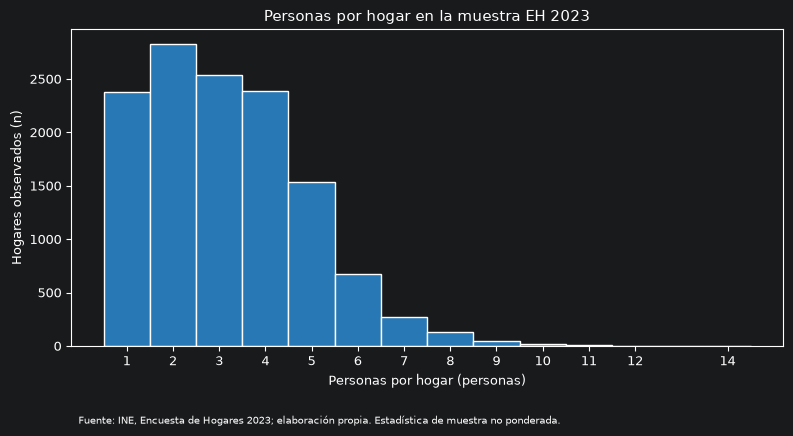

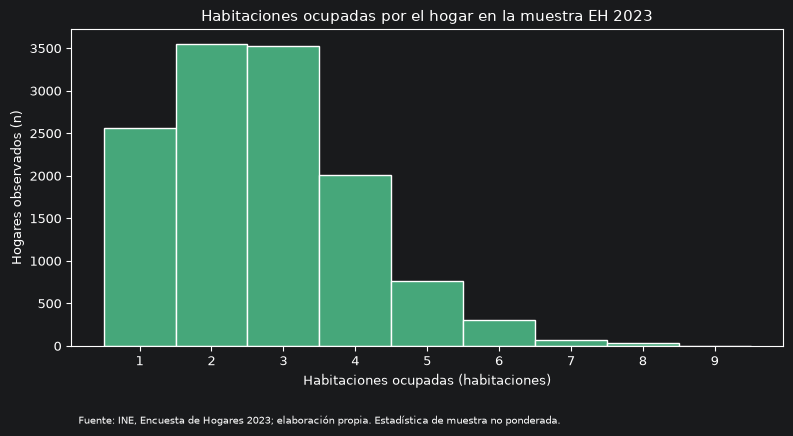

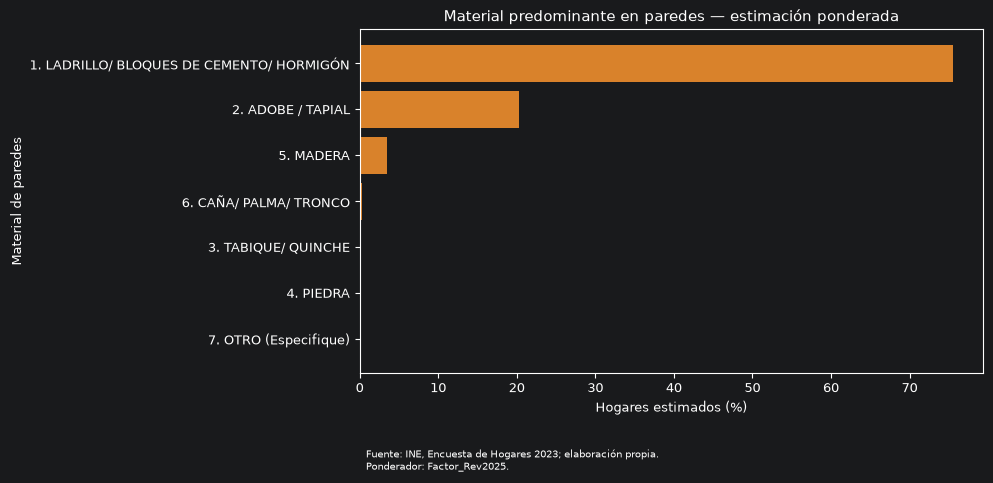

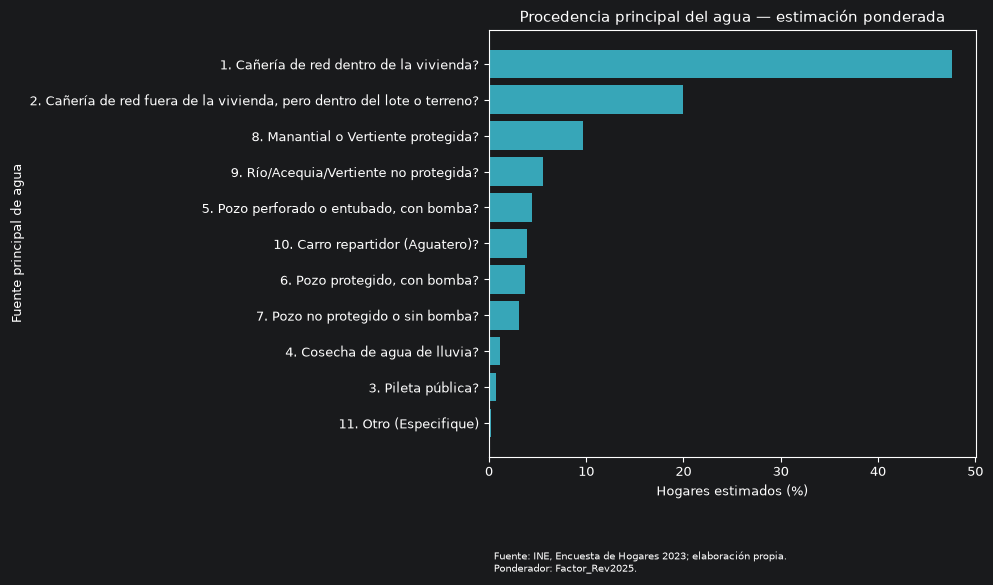

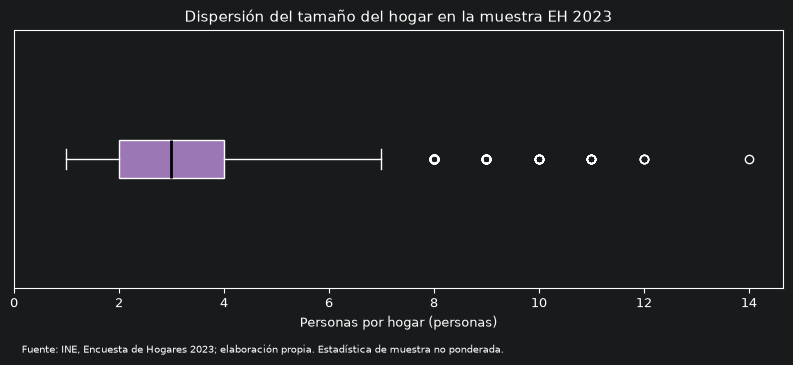

Interpretación de figura 1: La figura 1 resume 12,815 hogares: media 3.17 personas, mediana 3 y Q1–Q3 de 2–4 personas.
Interpretación de figura 2: La figura 2 incluye 12,815 hogares; media 2.71, mediana 3, Q1=2 y Q3=3 habitaciones.
Interpretación de figura 3: La figura 3 estima que “1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN” representa 75.57 % y “2. ADOBE / TAPIAL” 20.30 % de los hogares ponderados; las bases muestrales son n=9,702 y n=2,411.
Interpretación de figura 4: La figura 4 estima 47.66 % para “1. Cañería de red dentro de la vivienda?” y 19.97 % para “2. Cañería de red fuera de la vivienda, pero dentro del lote o terreno?”; sus frecuencias de muestra son 6,817 y 2,465 hogares.
Interpretación de figura 5: La figura 5 muestra mediana de 3 personas e intervalo intercuartílico de 2–4; el rango observado va de 1 a 14 personas.


In [8]:
figuras_interpretadas = []

def guardar_figura(figura, nombre):
    figura.tight_layout()
    figura.savefig(CARPETA_EXPORTACIONES / nombre, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figura)

def texto_fuente(ax, ponderada=False):
    fuente = "Fuente: INE, Encuesta de Hogares 2023; elaboración propia."
    fuente += f"\nPonderador: {PESO}." if ponderada else " Estadística de muestra no ponderada."
    ax.text(0.01, -0.22, fuente, transform=ax.transAxes, fontsize=7, va="top")

# Figura 1: histograma de personas por hogar.
serie = datos["totper"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
bordes = np.arange(int(serie.min()) - 0.5, int(serie.max()) + 1.5, 1)
ax.hist(serie, bins=bordes, color="#2878B5", edgecolor="white")
ax.set(title="Personas por hogar en la muestra EH 2023", xlabel="Personas por hogar (personas)", ylabel="Hogares observados (n)")
ax.set_xticks(sorted(serie.unique()))
texto_fuente(ax)
guardar_figura(fig, "grafico_01_histograma_personas_hogar.png")
figuras_interpretadas.append(f"La figura 1 resume {len(serie):,} hogares: media {serie.mean():.2f} personas, mediana {serie.median():.0f} y Q1–Q3 de {serie.quantile(.25):.0f}–{serie.quantile(.75):.0f} personas.")

# Figura 2: histograma de habitaciones ocupadas.
serie = datos["s06a_16"].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
bordes = np.arange(int(serie.min()) - 0.5, int(serie.max()) + 1.5, 1)
ax.hist(serie, bins=bordes, color="#46A77A", edgecolor="white")
ax.set(title="Habitaciones ocupadas por el hogar en la muestra EH 2023", xlabel="Habitaciones ocupadas (habitaciones)", ylabel="Hogares observados (n)")
ax.set_xticks(sorted(serie.unique()))
texto_fuente(ax)
guardar_figura(fig, "grafico_02_histograma_habitaciones.png")
figuras_interpretadas.append(f"La figura 2 incluye {len(serie):,} hogares; media {serie.mean():.2f}, mediana {serie.median():.0f}, Q1={serie.quantile(.25):.0f} y Q3={serie.quantile(.75):.0f} habitaciones.")

# Figura 3: porcentaje ponderado por material de paredes.
tabla = frecuencias["s06a_03"].sort_values("porcentaje_ponderado", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(tabla["categoria_INE"], tabla["porcentaje_ponderado"], color="#D9822B")
ax.invert_yaxis()
ax.set(title="Material predominante en paredes — estimación ponderada", xlabel="Hogares estimados (%)", ylabel="Material de paredes")
texto_fuente(ax, ponderada=True)
guardar_figura(fig, "grafico_03_barras_material_paredes.png")
top = tabla.iloc[0]
segundo = tabla.iloc[1]
figuras_interpretadas.append(f"La figura 3 estima que “{top['categoria_INE']}” representa {top['porcentaje_ponderado']:.2f} % y “{segundo['categoria_INE']}” {segundo['porcentaje_ponderado']:.2f} % de los hogares ponderados; las bases muestrales son n={int(top['frecuencia_muestra']):,} y n={int(segundo['frecuencia_muestra']):,}.")

# Figura 4: porcentaje ponderado por fuente de agua.
tabla = frecuencias["s06a_07"].sort_values("porcentaje_ponderado", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(tabla["categoria_INE"], tabla["porcentaje_ponderado"], color="#37A6B8")
ax.invert_yaxis()
ax.set(title="Procedencia principal del agua — estimación ponderada", xlabel="Hogares estimados (%)", ylabel="Fuente principal de agua")
texto_fuente(ax, ponderada=True)
top = tabla.iloc[0]
segundo = tabla.iloc[1]
figuras_interpretadas.append(f"La figura 4 estima {top['porcentaje_ponderado']:.2f} % para “{top['categoria_INE']}” y {segundo['porcentaje_ponderado']:.2f} % para “{segundo['categoria_INE']}”; sus frecuencias de muestra son {int(top['frecuencia_muestra']):,} y {int(segundo['frecuencia_muestra']):,} hogares.")
guardar_figura(fig, "grafico_04_barras_fuente_agua.png")

# Figura 5: boxplot de personas por hogar.
serie = datos["totper"].dropna()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot(serie, orientation="horizontal", patch_artist=True, boxprops={"facecolor": "#9B78B5"}, medianprops={"color": "black", "linewidth": 2})
ax.set(title="Dispersión del tamaño del hogar en la muestra EH 2023", xlabel="Personas por hogar (personas)", yticks=[], ylabel="")
ax.set_xlim(left=0)
texto_fuente(ax)
guardar_figura(fig, "grafico_05_boxplot_personas_hogar.png")
q1, mediana, q3 = serie.quantile([.25, .5, .75])
figuras_interpretadas.append(f"La figura 5 muestra mediana de {mediana:.0f} personas e intervalo intercuartílico de {q1:.0f}–{q3:.0f}; el rango observado va de {serie.min():.0f} a {serie.max():.0f} personas.")

assert len(list(CARPETA_EXPORTACIONES.glob("grafico_*.png"))) == 5
for i, interpretacion in enumerate(figuras_interpretadas, 1):
    print(f"Interpretación de figura {i}: {interpretacion}")

## 9. Preguntas analíticas
El plan combina dos preguntas descriptivas, dos comparativas y una relacional. Las comparaciones y asociaciones son descriptivas y no permiten atribuir causalidad. El análisis relacional se propone como correlación de Spearman, sin inferencia causal.

In [9]:
plan_preguntas = pd.DataFrame([
    {"tipo": "Descriptiva", "pregunta": "¿Qué materiales predominan en las paredes de las viviendas?", "variables": "s06a_03; Factor_Rev2025", "tecnica": "Frecuencias, porcentajes y estimación ponderada"},
    {"tipo": "Descriptiva", "pregunta": "¿Cuál es la distribución de las fuentes principales de agua?", "variables": "s06a_07; Factor_Rev2025", "tecnica": "Frecuencias, porcentajes y estimación ponderada"},
    {"tipo": "Comparativa", "pregunta": "¿Cómo varía el material de paredes entre áreas urbana y rural?", "variables": "s06a_03; area; Factor_Rev2025", "tecnica": "Tabla cruzada de porcentajes ponderados por área"},
    {"tipo": "Comparativa", "pregunta": "¿Cómo difiere el número de habitaciones ocupadas entre áreas urbana y rural?", "variables": "s06a_16; area; Factor_Rev2025", "tecnica": "Medias y distribuciones ponderadas por área; contraste descriptivo"},
    {"tipo": "Relacional", "pregunta": "¿Qué asociación descriptiva existe entre personas por hogar y habitaciones ocupadas?", "variables": "totper; s06a_16", "tecnica": "Correlación de Spearman y diagrama/tabulación exploratoria; sin causalidad"},
])
plan_preguntas.to_csv(CARPETA_EXPORTACIONES / "plan_preguntas.csv", index=False, encoding="utf-8-sig")
display(plan_preguntas)

,tipo,pregunta,variables,tecnica
0,Descriptiva,¿Qué materiales predominan en las paredes de las viviendas?,s06a_03; Factor_Rev2025,"Frecuencias, porcentajes y estimación ponderada"
1,Descriptiva,¿Cuál es la distribución de las fuentes principales de agua?,s06a_07; Factor_Rev2025,"Frecuencias, porcentajes y estimación ponderada"
2,Comparativa,¿Cómo varía el material de paredes entre áreas urbana y rural?,s06a_03; area; Factor_Rev2025,Tabla cruzada de porcentajes ponderados por área
3,Comparativa,¿Cómo difiere el número de habitaciones ocupadas entre áreas urbana y rural?,s06a_16; area; Factor_Rev2025,Medias y distribuciones ponderadas por área; contraste descriptivo
4,Relacional,¿Qué asociación descriptiva existe entre personas por hogar y habitaciones ocupadas?,totper; s06a_16,Correlación de Spearman y diagrama/tabulación exploratoria; sin causalidad


## 10. Hallazgos, limitaciones y conclusiones
Los hallazgos se derivan de las tablas de salida. Las estimaciones ponderadas son puntuales; no se presentan como resultados con intervalos de confianza.

In [10]:
hallazgos = [
    interpretaciones_descriptivas[0],
    interpretaciones_descriptivas[1],
    interpretaciones_descriptivas[3],
    interpretaciones_descriptivas[4],
    f"El peso revisado suma {datos[PESO].sum():,.2f} hogares estimados en el conjunto de registros; el peso original factor suma {datos['factor'].sum():,.2f}. Ambos están completos, pero las estimaciones principales usan {PESO} por corresponder a la revisión 2025 informada por el INE.",
]
limitaciones = [
    "La Encuesta de Hogares es una muestra; las cifras muestrales sin ponderar no representan por sí solas a todos los hogares bolivianos.",
    "Se calculan estimaciones puntuales con Factor_Rev2025, pero no errores estándar, intervalos de confianza ni pruebas que incorporen completamente estratos y UPM.",
    "Las preguntas condicionadas generan faltantes estructurales; no se imputan ni se convierten en categorías sustantivas.",
    "La copia local contiene 37 columnas, mientras el diccionario público de ANDA lista 36; la columna adicional Factor_Rev2025 se identifica como revisión de ponderador.",
    "Los identificadores de UPM y estrato están anonimizados; los archivos agregados omiten identificadores y texto libre para proteger registros individuales.",
]
conclusiones = [
    f"La descripción de {len(datos):,} viviendas/hogares permite caracterizar materiales, agua y espacio doméstico en el conjunto de hogares observados.",
    f"Las tablas ponderadas con {PESO} ofrecen estimaciones puntuales coherentes con el factor revisado que acompaña a la base y con la nota de actualización del INE.",
    "Los resultados son descriptivos; para publicar inferencias con precisión muestral se requiere implementar el diseño complejo y documentar sus estimadores de varianza.",
]

for i, texto in enumerate(hallazgos, 1):
    print(f"Hallazgo {i}: {texto}")
print("Limitaciones:")
for i, texto in enumerate(limitaciones, 1):
    print(f"{i}. {texto}")
print("Conclusiones:")
for i, texto in enumerate(conclusiones, 1):
    print(f"{i}. {texto}")

resumen_resultados = pd.DataFrame({"tipo": ["Hallazgo"] * len(hallazgos) + ["Limitación"] * len(limitaciones) + ["Conclusión"] * len(conclusiones), "texto": hallazgos + limitaciones + conclusiones})
resumen_resultados.to_csv(CARPETA_EXPORTACIONES / "resumen_resultados.csv", index=False, encoding="utf-8-sig")
(CARPETA_EXPORTACIONES / "resumen_resultados.md").write_text(
    "# Resumen de resultados verificables\n\n" +
    "## Hallazgos\n" + "\n".join(f"{i}. {x}" for i, x in enumerate(hallazgos, 1)) +
    "\n\n## Limitaciones\n" + "\n".join(f"{i}. {x}" for i, x in enumerate(limitaciones, 1)) +
    "\n\n## Conclusiones\n" + "\n".join(f"{i}. {x}" for i, x in enumerate(conclusiones, 1)) + "\n",
    encoding="utf-8",
)

Hallazgo 1: En la muestra, el tamaño del hogar (`totper`) tiene n=12,815, media 3.17 personas, mediana 3, Q1=2, Q3=4 y rango 1–14.
Hallazgo 2: Las habitaciones ocupadas (`s06a_16`) registran media 2.71, mediana 3 y rango 1–9; el 50 % central está entre Q1=2 y Q3=3.
Hallazgo 3: La moda muestral de material de paredes es “1. LADRILLO/ BLOQUES DE CEMENTO/ HORMIGÓN”, con 9,702 hogares (75.71 %); su porcentaje ponderado es 75.57 %.
Hallazgo 4: La moda muestral de fuente de agua es “1. Cañería de red dentro de la vivienda?”, con 6,817 hogares (53.20 %); su porcentaje ponderado es 47.66 %.
Hallazgo 5: El peso revisado suma 3,799,194.10 hogares estimados en el conjunto de registros; el peso original factor suma 3,898,750.27. Ambos están completos, pero las estimaciones principales usan Factor_Rev2025 por corresponder a la revisión 2025 informada por el INE.
Limitaciones:
1. La Encuesta de Hogares es una muestra; las cifras muestrales sin ponderar no representan por sí solas a todos los hogares

2136

## 11. Resultado — archivos exportados
Se presentan las rutas creadas y la comprobación final de tablas, cinco figuras y dimensiones. No se exporta una tabla de muestra ni ningún identificador individual.

In [11]:
archivos_csv = sorted(CARPETA_EXPORTACIONES.glob("*.csv"))
archivos_png = sorted(CARPETA_EXPORTACIONES.glob("grafico_*.png"))
print(f"Registros: {len(datos):,}; variables: {datos.shape[1]}")
print("CSV agregados:")
for ruta in archivos_csv:
    print(f"- {ruta.relative_to(ROOT)} ({ruta.stat().st_size:,} bytes)")
print("Figuras PNG:")
for ruta in archivos_png:
    print(f"- {ruta.relative_to(ROOT)} ({ruta.stat().st_size:,} bytes)")
assert len(archivos_png) == 5
assert len(datos) > 600
assert not any("muestra" in p.name.lower() or "registro" in p.name.lower() for p in archivos_csv)

Registros: 12,815; variables: 37
CSV agregados:
- exportaciones_eh2023/auditoria_calidad.csv (1,917 bytes)
- exportaciones_eh2023/diccionario_variables.csv (10,311 bytes)
- exportaciones_eh2023/estadistica_descriptiva.csv (662 bytes)
- exportaciones_eh2023/frecuencias_categoria_1.csv (775 bytes)
- exportaciones_eh2023/frecuencias_categoria_2.csv (1,317 bytes)
- exportaciones_eh2023/plan_preguntas.csv (877 bytes)
- exportaciones_eh2023/resumen_resultados.csv (2,214 bytes)
Figuras PNG:
- exportaciones_eh2023/grafico_01_histograma_personas_hogar.png (51,713 bytes)
- exportaciones_eh2023/grafico_02_histograma_habitaciones.png (53,948 bytes)
- exportaciones_eh2023/grafico_03_barras_material_paredes.png (86,037 bytes)
- exportaciones_eh2023/grafico_04_barras_fuente_agua.png (125,348 bytes)
- exportaciones_eh2023/grafico_05_boxplot_personas_hogar.png (38,959 bytes)
